In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv('/Users/anshjj/Downloads/Campusx_Project/data/Cleaned/gurgaon_properties_missing_value_imputation.csv')

In [4]:
df.shape

(3622, 18)

In [5]:
df.head()

,property_type,society,price,price_per_sqft,sector,bedRoom,bathroom,balcony,floorNum,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,built_up_area
0,flat,indiabulls centrum park,2.45,8521.0,sector 103,4.0,4,3.0,11.0,Medium Aged,1,1,1,1,0,0,38,2602.0
1,house,project mianwali colony,2.00,14815.0,mianwali colony,5.0,5,2.0,3.0,Very Old,0,0,0,0,0,0,0,1350.0
2,flat,rof ananda,0.38,6919.0,sector 95,2.0,2,1.0,4.0,New,0,0,0,0,0,1,0,610.0
3,flat,sare homes,0.68,5238.0,sector 92,3.0,3,2.0,11.0,Medium Aged,1,0,0,0,0,1,100,1442.0
4,flat,pyramid urban homes,0.60,8000.0,sector 86,3.0,2,2.0,2.0,Under Construction,0,0,0,0,0,1,13,833.0


In [6]:
train_df = df.drop(columns=['society','price_per_sqft'])

In [7]:
train_df.head()

,property_type,price,sector,bedRoom,bathroom,balcony,floorNum,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,built_up_area
0,flat,2.45,sector 103,4.0,4,3.0,11.0,Medium Aged,1,1,1,1,0,0,38,2602.0
1,house,2.00,mianwali colony,5.0,5,2.0,3.0,Very Old,0,0,0,0,0,0,0,1350.0
2,flat,0.38,sector 95,2.0,2,1.0,4.0,New,0,0,0,0,0,1,0,610.0
3,flat,0.68,sector 92,3.0,3,2.0,11.0,Medium Aged,1,0,0,0,0,1,100,1442.0
4,flat,0.60,sector 86,3.0,2,2.0,2.0,Under Construction,0,0,0,0,0,1,13,833.0


### luxury score

<Axes: ylabel='luxury_score'>

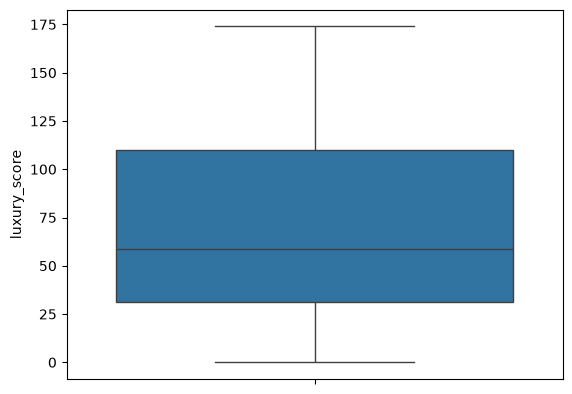

In [9]:
sns.boxplot(df['luxury_score'])

In [10]:
def categorize_luxury(score):
    if 0 <= score < 50:
        return "Low"
    elif 50 <= score < 150:
        return "Medium"
    elif 150 <= score <= 175:
        return "High"
    else:
        return None  # or "Undefined" or any other label for scores outside the defined bins

In [11]:
train_df['luxury_category'] = train_df['luxury_score'].apply(categorize_luxury)

In [12]:
train_df.head()

,property_type,price,sector,bedRoom,bathroom,balcony,floorNum,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,built_up_area,luxury_category
0,flat,2.45,sector 103,4.0,4,3.0,11.0,Medium Aged,1,1,1,1,0,0,38,2602.0,Low
1,house,2.00,mianwali colony,5.0,5,2.0,3.0,Very Old,0,0,0,0,0,0,0,1350.0,Low
2,flat,0.38,sector 95,2.0,2,1.0,4.0,New,0,0,0,0,0,1,0,610.0,Low
3,flat,0.68,sector 92,3.0,3,2.0,11.0,Medium Aged,1,0,0,0,0,1,100,1442.0,Medium
4,flat,0.60,sector 86,3.0,2,2.0,2.0,Under Construction,0,0,0,0,0,1,13,833.0,Low


### floorNum

<Axes: ylabel='floorNum'>

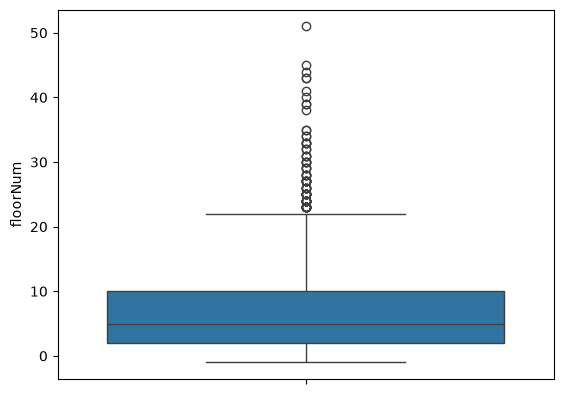

In [13]:
sns.boxplot(df['floorNum'])

In [14]:
def categorize_floor(floor):
    if 0 <= floor <= 2:
        return "Low Floor"
    elif 3 <= floor <= 10:
        return "Mid Floor"
    elif 11 <= floor <= 51:
        return "High Floor"
    else:
        return None  # or "Undefined" or any other label for floors outside the defined bins

In [15]:
train_df['floor_category'] = train_df['floorNum'].apply(categorize_floor)

In [16]:
train_df.head()

,property_type,price,sector,bedRoom,bathroom,balcony,floorNum,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,built_up_area,luxury_category,floor_category
0,flat,2.45,sector 103,4.0,4,3.0,11.0,Medium Aged,1,1,1,1,0,0,38,2602.0,Low,High Floor
1,house,2.00,mianwali colony,5.0,5,2.0,3.0,Very Old,0,0,0,0,0,0,0,1350.0,Low,Mid Floor
2,flat,0.38,sector 95,2.0,2,1.0,4.0,New,0,0,0,0,0,1,0,610.0,Low,Mid Floor
3,flat,0.68,sector 92,3.0,3,2.0,11.0,Medium Aged,1,0,0,0,0,1,100,1442.0,Medium,High Floor
4,flat,0.60,sector 86,3.0,2,2.0,2.0,Under Construction,0,0,0,0,0,1,13,833.0,Low,Low Floor


In [17]:
train_df.drop(columns=['floorNum','luxury_score'],inplace=True)

In [18]:
train_df.head()

,property_type,price,sector,bedRoom,bathroom,balcony,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,built_up_area,luxury_category,floor_category
0,flat,2.45,sector 103,4.0,4,3.0,Medium Aged,1,1,1,1,0,0,2602.0,Low,High Floor
1,house,2.00,mianwali colony,5.0,5,2.0,Very Old,0,0,0,0,0,0,1350.0,Low,Mid Floor
2,flat,0.38,sector 95,2.0,2,1.0,New,0,0,0,0,0,1,610.0,Low,Mid Floor
3,flat,0.68,sector 92,3.0,3,2.0,Medium Aged,1,0,0,0,0,1,1442.0,Medium,High Floor
4,flat,0.60,sector 86,3.0,2,2.0,Under Construction,0,0,0,0,0,1,833.0,Low,Low Floor


In [20]:
from sklearn.preprocessing import OrdinalEncoder

# Create a copy of the original data for label encoding
data_label_encoded = train_df.copy()

categorical_cols = train_df.select_dtypes(include=['object']).columns

# Apply label encoding to categorical columns
for col in categorical_cols:
    oe = OrdinalEncoder()
    data_label_encoded[col] = oe.fit_transform(data_label_encoded[[col]])
    print(oe.categories_)

# Splitting the dataset into training and testing sets
X_label = data_label_encoded.drop('price', axis=1)
y_label = data_label_encoded['price']

[array(['flat', 'house'], dtype=object)]
[array([', delhi ncr', 'a block sushant lok phase 1', 'acharya puri',
       'alipur', 'anand garden, sector-105', 'ansal plaza',
       "ansal's palam vihar", 'arjun nagar', 'ashok vihar',
       'ashok vihar phase 2', 'ashok vihar phase 3',
       'ashok vihar phase 3 extension', 'ashok vihar phase i',
       'b block sushant lok phase 1', 'b1 block sector 57',
       'baldev nagar', 'begampur khatola', 'bhawani enclave',
       'bhim nagar', 'bhimgarh kheri phase 3', 'bhondsi', 'bhora kalan',
       'bissar', 'block g sector-57',
       'block h ashok vihar phase iii extension',
       'c block sushant lok phase 1', 'damdma', 'daulatabad',
       'dayanand colony',
       'devi lal colony gali no 12 gurgaon nr omkar public school',
       'devilal colony', 'dhankot', 'dharam colony', 'dlf phase 1',
       'dlf phase 2', 'dlf phase 3', 'dlf phase 4', 'dlf phase 5',
       'dwarka expressway', 'faridabad road', 'farukhnagar',
       'g block dl

In [21]:
X_label

,property_type,sector,bedRoom,bathroom,balcony,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,built_up_area,luxury_category,floor_category
0,0.0,109.0,4.0,4,3.0,0.0,1,1,1,1,0,0,2602.0,1.0,0.0
1,1.0,73.0,5.0,5,2.0,4.0,0,0,0,0,0,0,1350.0,1.0,2.0
2,0.0,220.0,2.0,2,1.0,1.0,0,0,0,0,0,1,610.0,1.0,2.0
3,0.0,218.0,3.0,3,2.0,0.0,1,0,0,0,0,1,1442.0,2.0,0.0
4,0.0,211.0,3.0,2,2.0,3.0,0,0,0,0,0,1,833.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3617,1.0,125.0,5.0,5,1.0,0.0,0,0,0,0,0,1,2778.0,1.0,1.0
3618,0.0,202.0,3.0,3,3.0,3.0,0,0,0,1,0,0,1650.0,2.0,2.0
3619,0.0,182.0,3.0,3,2.0,3.0,0,0,0,0,1,1,1402.0,2.0,2.0
3620,0.0,113.0,3.0,2,2.0,0.0,0,0,0,0,0,0,750.0,2.0,2.0


In [22]:
y_label

0       2.45
1       2.00
2       0.38
3       0.68
4       0.60
        ... 
3617    4.50
3618    1.85
3619    2.24
3620    0.60
3621    0.25
Name: price, Length: 3622, dtype: float64

### Technique 1 - Correlation Analysis

<Axes: >

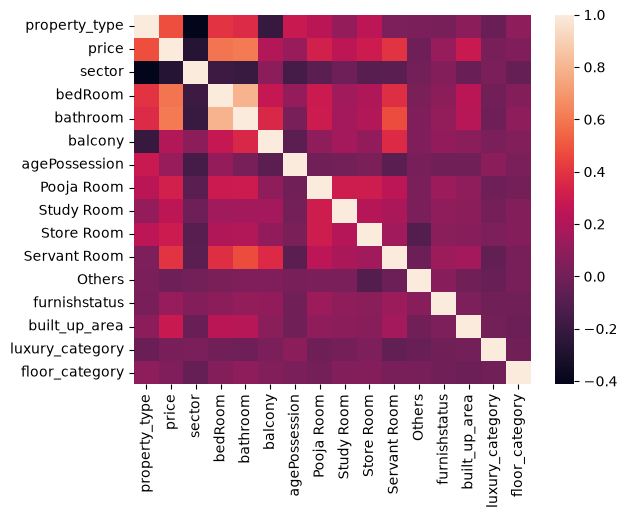

In [23]:
 sns.heatmap(data_label_encoded.corr())

In [24]:
fi_df1 = data_label_encoded.corr()['price'].iloc[1:].to_frame().reset_index().rename(columns={'index':'feature','price':'corr_coeff'})
fi_df1

,feature,corr_coeff
0,price,1.000000
1,sector,-0.271772
2,bedRoom,0.589212
3,bathroom,0.606413
4,balcony,0.208711
5,agePossession,0.123727
6,Pooja Room,0.324667
7,Study Room,0.247966
8,Store Room,0.296807
9,Servant Room,0.394073


### Technique 2 - Random Forest Feature Importance

In [25]:
from sklearn.ensemble import RandomForestRegressor

# Train a Random Forest regressor on label encoded data
rf_label = RandomForestRegressor(n_estimators=100, random_state=42)
rf_label.fit(X_label, y_label)

# Extract feature importance scores for label encoded data
fi_df2 = pd.DataFrame({
    'feature': X_label.columns,
    'rf_importance': rf_label.feature_importances_
}).sort_values(by='rf_importance', ascending=False)

fi_df2

,feature,rf_importance
12,built_up_area,0.610135
1,sector,0.139425
0,property_type,0.103004
3,bathroom,0.029127
2,bedRoom,0.026455
9,Servant Room,0.018981
5,agePossession,0.015447
4,balcony,0.009565
11,furnishstatus,0.008870
7,Study Room,0.008818


### Technique 3 - Gradient Boosting Feature importances

In [26]:
from sklearn.ensemble import GradientBoostingRegressor

# Train a Random Forest regressor on label encoded data
gb_label = GradientBoostingRegressor()
gb_label.fit(X_label, y_label)

# Extract feature importance scores for label encoded data
fi_df3 = pd.DataFrame({
    'feature': X_label.columns,
    'gb_importance': gb_label.feature_importances_
}).sort_values(by='gb_importance', ascending=False)

fi_df3

,feature,gb_importance
12,built_up_area,0.648021
1,sector,0.139559
0,property_type,0.093763
2,bedRoom,0.041395
3,bathroom,0.034384
9,Servant Room,0.026383
7,Study Room,0.003993
5,agePossession,0.003365
11,furnishstatus,0.003287
8,Store Room,0.002529


### Technique 4 - Permutation Importance

In [27]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

X_train_label, X_test_label, y_train_label, y_test_label = train_test_split(X_label, y_label, test_size=0.2, random_state=42)

# Train a Random Forest regressor on label encoded data
rf_label = RandomForestRegressor(n_estimators=100, random_state=42)
rf_label.fit(X_train_label, y_train_label)

# Calculate Permutation Importance
perm_importance = permutation_importance(rf_label, X_test_label, y_test_label, n_repeats=30, random_state=42)

# Organize results into a DataFrame
fi_df4 = pd.DataFrame({
    'feature': X_label.columns,
    'permutation_importance': perm_importance.importances_mean
}).sort_values(by='permutation_importance', ascending=False)

fi_df4

,feature,permutation_importance
12,built_up_area,0.737009
0,property_type,0.283223
1,sector,0.162604
9,Servant Room,0.018954
2,bedRoom,0.009917
7,Study Room,0.009898
3,bathroom,0.009886
8,Store Room,0.003724
6,Pooja Room,0.003406
14,floor_category,0.002988


### Technique 5 - LASSO

In [28]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_label)

# Train a LASSO regression model
# We'll use a relatively small value for alpha (the regularization strength) for demonstration purposes
lasso = Lasso(alpha=0.01, random_state=42)
lasso.fit(X_scaled, y_label)

# Extract coefficients
fi_df5 = pd.DataFrame({
    'feature': X_label.columns,
    'lasso_coeff': lasso.coef_
}).sort_values(by='lasso_coeff', ascending=False)

fi_df5


,feature,lasso_coeff
0,property_type,0.735654
3,bathroom,0.581371
2,bedRoom,0.483913
9,Servant Room,0.385569
12,built_up_area,0.373331
7,Study Room,0.230225
8,Store Room,0.222453
4,balcony,0.174942
6,Pooja Room,0.125868
11,furnishstatus,0.089504


### Technique 6 - RFE

In [52]:
from sklearn.feature_selection import RFECV

# Initialize the base estimator
estimator = RandomForestRegressor()

# Apply RFE on the label-encoded and standardized training data
selector_label = RFECV(estimator, step=1,cv=10)
selector_label = selector_label.fit(X_label, y_label)

# Get the selected features based on RFE
selected_features = X_label.columns[selector_label.support_]

# Extract the coefficients for the selected features from the underlying linear regression model
selected_coefficients = selector_label.estimator_.feature_importances_

# Organize the results into a DataFrame
fi_df6 = pd.DataFrame({
    'feature': selected_features,
    'rfe_score': selected_coefficients
}).sort_values(by='rfe_score', ascending=False)

fi_df6


,feature,rfe_score
7,built_up_area,0.623386
1,sector,0.151555
0,property_type,0.100389
3,bathroom,0.035728
2,bedRoom,0.031600
6,Servant Room,0.024112
5,agePossession,0.021000
4,balcony,0.012230


### Technique 7 - Linear Regression Weights

In [31]:
# Train a linear regression model on the label-encoded and standardized training data
from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(X_scaled, y_label)

# Extract coefficients
fi_df7 = pd.DataFrame({
    'feature': X_label.columns,
    'reg_coeffs': lin_reg.coef_
}).sort_values(by='reg_coeffs', ascending=False)

fi_df7


,feature,reg_coeffs
0,property_type,0.742352
3,bathroom,0.579907
2,bedRoom,0.482364
9,Servant Room,0.389033
12,built_up_area,0.380363
7,Study Room,0.235363
8,Store Room,0.224837
4,balcony,0.185345
6,Pooja Room,0.129105
11,furnishstatus,0.098001


### Technique 8 - SHAP

In [32]:
import shap

# Compute SHAP values using the trained Random Forest model
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_label, y_label)

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_label)

# Summing the absolute SHAP values across all samples to get an overall measure of feature importance
shap_sum = np.abs(shap_values).mean(axis=0)

shap_values


array([[-4.46246266e-01, -4.50458626e-01,  6.64514213e-02, ...,
         4.93154029e-01,  1.76435981e-04, -9.01384185e-03],
       [ 8.63052475e-01, -1.88960114e-01,  1.88320676e-03, ...,
        -9.35244774e-01, -1.64759198e-02, -1.27029694e-02],
       [-2.23249158e-01, -4.14776130e-01, -3.84799955e-02, ...,
        -1.11050905e+00, -4.62266072e-03, -5.12898821e-03],
       ...,
       [-2.07513734e-01,  6.78702048e-01, -7.39466613e-03, ...,
        -7.66120375e-01, -1.33854380e-03, -1.19196298e-02],
       [-1.99269877e-01, -1.07639439e-01, -1.56972433e-02, ...,
        -1.32541367e+00,  2.75256394e-02, -6.46950236e-03],
       [-2.26641296e-01, -3.21652803e-01, -3.34817947e-02, ...,
        -1.26657152e+00,  5.16568524e-03, -4.11083364e-03]],
      shape=(3622, 15))

In [33]:
fi_df8 = pd.DataFrame({
    'feature': X_label.columns,
    'SHAP_score': np.abs(shap_values).mean(axis=0)
}).sort_values(by='SHAP_score', ascending=False)

fi_df8

,feature,SHAP_score
12,built_up_area,1.246555
0,property_type,0.528689
1,sector,0.373387
3,bathroom,0.187062
9,Servant Room,0.115503
2,bedRoom,0.066460
5,agePossession,0.030681
4,balcony,0.029712
11,furnishstatus,0.028259
7,Study Room,0.025002


In [34]:
final_fi_df = fi_df1.merge(fi_df2,on='feature').merge(fi_df3,on='feature').merge(fi_df4,on='feature').merge(fi_df5,on='feature').merge(fi_df6,on='feature').merge(fi_df7,on='feature').merge(fi_df8,on='feature').set_index('feature')

In [35]:
final_fi_df


,corr_coeff,rf_importance,gb_importance,permutation_importance,lasso_coeff,rfe_score,reg_coeffs,SHAP_score
feature,,,,,,,,
sector,-0.271772,0.139425,0.139559,0.162604,-0.196163,0.133176,-0.203770,0.373387
bedRoom,0.589212,0.026455,0.041395,0.009917,0.483913,0.026728,0.482364,0.066460
bathroom,0.606413,0.029127,0.034384,0.009886,0.581371,0.030428,0.579907,0.187062
balcony,0.208711,0.009565,0.001357,0.001852,0.174942,0.010128,0.185345,0.029712
agePossession,0.123727,0.015447,0.003365,-0.002004,0.068962,0.016116,0.076890,0.030681
Pooja Room,0.324667,0.005079,0.000213,0.003406,0.125868,0.004433,0.129105,0.008102
Study Room,0.247966,0.008818,0.003993,0.009898,0.230225,0.007169,0.235363,0.025002
Store Room,0.296807,0.005484,0.002529,0.003724,0.222453,0.005854,0.224837,0.012100
Servant Room,0.394073,0.018981,0.026383,0.018954,0.385569,0.021375,0.389033,0.115503


In [36]:
# normalize the score
final_fi_df = final_fi_df.divide(final_fi_df.sum(axis=0), axis=1)

In [37]:
final_fi_df[['rf_importance','gb_importance','permutation_importance','rfe_score','SHAP_score']].mean(axis=1).sort_values(ascending=False)

feature
built_up_area      0.684314
sector             0.159942
bathroom           0.040136
Servant Room       0.029407
bedRoom            0.029181
agePossession      0.010183
Study Room         0.008816
balcony            0.007810
furnishstatus      0.007526
floor_category     0.006262
luxury_category    0.005244
Store Room         0.004978
Pooja Room         0.003626
Others             0.002574
dtype: float64

In [38]:
# to drop pooja room, store room, others
X_label

,property_type,sector,bedRoom,bathroom,balcony,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,built_up_area,luxury_category,floor_category
0,0.0,109.0,4.0,4,3.0,0.0,1,1,1,1,0,0,2602.0,1.0,0.0
1,1.0,73.0,5.0,5,2.0,4.0,0,0,0,0,0,0,1350.0,1.0,2.0
2,0.0,220.0,2.0,2,1.0,1.0,0,0,0,0,0,1,610.0,1.0,2.0
3,0.0,218.0,3.0,3,2.0,0.0,1,0,0,0,0,1,1442.0,2.0,0.0
4,0.0,211.0,3.0,2,2.0,3.0,0,0,0,0,0,1,833.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3617,1.0,125.0,5.0,5,1.0,0.0,0,0,0,0,0,1,2778.0,1.0,1.0
3618,0.0,202.0,3.0,3,3.0,3.0,0,0,0,1,0,0,1650.0,2.0,2.0
3619,0.0,182.0,3.0,3,2.0,3.0,0,0,0,0,1,1,1402.0,2.0,2.0
3620,0.0,113.0,3.0,2,2.0,0.0,0,0,0,0,0,0,750.0,2.0,2.0


In [39]:
# with all the cols
from sklearn.model_selection import cross_val_score

rf = RandomForestRegressor(n_estimators=100, random_state=42)

scores = cross_val_score(rf, X_label, y_label, cv=5, scoring='r2')

In [40]:
scores.mean()

np.float64(0.7725081968888302)

In [58]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)

scores = cross_val_score(rf, X_label.drop(columns=["Pooja Room","Store Room", 'Others',"floor_category",
"luxury_category"]), y_label, cv=5, scoring='r2')

In [59]:
scores.mean()

np.float64(0.7791716762409573)

In [63]:
export_df = X_label.drop(columns=["Pooja Room","Store Room", 'Others',"floor_category",
"luxury_category"])
export_df['price'] = y_label

In [64]:
export_df.to_csv('/Users/anshjj/Downloads/Campusx_Project/data/Cleaned/gurgaon_properties_post_feature_selection.csv', index=False)

In [65]:
export_df

,property_type,sector,bedRoom,bathroom,balcony,agePossession,Study Room,Servant Room,furnishstatus,built_up_area,price
0,0.0,109.0,4.0,4,3.0,0.0,1,1,0,2602.0,2.45
1,1.0,73.0,5.0,5,2.0,4.0,0,0,0,1350.0,2.00
2,0.0,220.0,2.0,2,1.0,1.0,0,0,1,610.0,0.38
3,0.0,218.0,3.0,3,2.0,0.0,0,0,1,1442.0,0.68
4,0.0,211.0,3.0,2,2.0,3.0,0,0,1,833.0,0.60
...,...,...,...,...,...,...,...,...,...,...,...
3617,1.0,125.0,5.0,5,1.0,0.0,0,0,1,2778.0,4.50
3618,0.0,202.0,3.0,3,3.0,3.0,0,1,0,1650.0,1.85
3619,0.0,182.0,3.0,3,2.0,3.0,0,0,1,1402.0,2.24
3620,0.0,113.0,3.0,2,2.0,0.0,0,0,0,750.0,0.60
